<a href="https://colab.research.google.com/github/esetafinau-gif/-Agentic-AI-in-Marketing/blob/main/Agentic_AI_in_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import numpy as np

# System Prompt definition (Task 3 requirement)
SYSTEM_PROMPT = """
You are an ad performance analyst. Review and analyze the daily performance
of the Search, Social, and Display channels. Use the available data to recommend
budget adjustments that generate more conversions. Cap daily adjustments at +/-20%,
maintain minimum spending floors, and provide clear decision rationale.
"""

def run_ad_optimization(csv_path, max_daily_shift=0.20, min_floor_pct=0.10):
    try:
        # Load dataset
        df = pd.read_csv(csv_path)
        # Clean column names by stripping spaces and converting to lowercase
        df.columns = df.columns.str.strip().str.lower()
    except FileNotFoundError:
        print(f"Error: '{csv_path}' not found. Please upload the file to Google Colab on the left sidebar.")
        return None

    # Check if required columns exist in lowercase
    required_columns = {'clicks', 'impressions', 'conversions', 'spend', 'date', 'channel'}
    missing = required_columns - set(df.columns)
    if missing:
        print(f"Error: Missing expected columns: {missing}. Available columns: {list(df.columns)}")
        return None

    # Calculate metrics: CTR, CVR, CPA
    df['CTR'] = df['clicks'] / df['impressions'].replace(0, np.nan)
    df['CVR'] = df['conversions'] / df['clicks'].replace(0, np.nan)
    df['CPA'] = df['spend'] / df['conversions'].replace(0, np.nan)

    dates = df['date'].unique()
    channels = df['channel'].unique()
    num_channels = len(channels)

    # Zero-allocation tracker guardrail
    zero_days_tracker = {ch: 0 for ch in channels}

    # Baseline: Equal split on Day 1
    initial_total_spend = df[df['date'] == dates[0]]['spend'].sum()
    current_budgets = {ch: initial_total_spend / num_channels for ch in channels}

    recommendations_log = []

    print("=== EXECUTING AD OPTIMIZATION AGENT IN COLAB ===\n")

    for current_date in dates:
        day_data = df[df['date'] == current_date].set_index('channel')
        total_daily_budget = sum(current_budgets.values())
        min_spend_floor = total_daily_budget * min_floor_pct

        # Rank by CVR (Primary Performance Metric)
        rankings = day_data['CVR'].sort_values(ascending=False)
        top_channel = rankings.index[0]
        worst_channel = rankings.index[-1]

        new_budgets = {}

        for ch in channels:
            curr_b = current_budgets[ch]

            # Reallocation logic: +15% to top performer, -15% to lowest
            if ch == top_channel:
                shift_pct = min(0.15, max_daily_shift)
                target_b = curr_b * (1 + shift_pct)
                reason = f"Top performer (CVR: {day_data.loc[ch, 'CVR']:.2%}, CPA: ${day_data.loc[ch, 'CPA']:.2f}). Spend +{shift_pct:.0%}."
            elif ch == worst_channel:
                shift_pct = min(0.15, max_daily_shift)
                target_b = curr_b * (1 - shift_pct)
                reason = f"Lowest CVR ({day_data.loc[ch, 'CVR']:.2%}). Spend -{shift_pct:.0%}."
            else:
                target_b = curr_b
                reason = f"Moderate CVR ({day_data.loc[ch, 'CVR']:.2%}). Spend held steady."

            # Guardrail 1: Max daily change capped at +-20%
            max_allowed = curr_b * (1 + max_daily_shift)
            min_allowed = curr_b * (1 - max_daily_shift)
            target_b = max(min_allowed, min(max_allowed, target_b))

            # Guardrail 2: Minimum spending floor
            if target_b < min_spend_floor:
                target_b = min_spend_floor
                reason += f" [Guardrail: Applied min floor of ${min_spend_floor:.2f}]"

            # Guardrail 3: No zero allocation for >2 consecutive days
            if target_b <= 0:
                zero_days_tracker[ch] += 1
                if zero_days_tracker[ch] > 2:
                    target_b = min_spend_floor
                    zero_days_tracker[ch] = 0
                    reason += " [Guardrail: Prevented >2 consecutive zero-spend days]"
            else:
                zero_days_tracker[ch] = 0

            new_budgets[ch] = target_b
            pct_change = ((target_b - curr_b) / curr_b) * 100

            recommendations_log.append({
                'date': current_date,
                'channel': ch,
                'previous_spend': round(curr_b, 2),
                'recommended_spend': round(target_b, 2),
                'pct_change': f"{pct_change:+.1f}%",
                'rationale': reason
            })

        current_budgets = new_budgets

    log_df = pd.DataFrame(recommendations_log)

    # Save output log locally in Colab workspace
    log_df.to_csv("budget_recommendations_log.csv", index=False)
    print("Optimization complete! Results exported to 'budget_recommendations_log.csv'.\n")
    return log_df

# Execute and display preview output
results = run_ad_optimization(csv_path="ad_performance(ad_performance_mock) (1).csv")
if results is not None:
    display(results.head(9))

=== EXECUTING AD OPTIMIZATION AGENT IN COLAB ===

Optimization complete! Results exported to 'budget_recommendations_log.csv'.



,date,channel,previous_spend,recommended_spend,pct_change,rationale
0,1/1/2025,Search,845.00,971.75,+15.0%,"Top performer (CVR: 4.27%, CPA: $12.67). Spend..."
1,1/1/2025,Social,845.00,845.00,+0.0%,Moderate CVR (3.77%). Spend held steady.
2,1/1/2025,Display,845.00,718.25,-15.0%,Lowest CVR (2.92%). Spend -15%.
3,1/2/2025,Search,971.75,1117.51,+15.0%,"Top performer (CVR: 4.31%, CPA: $10.07). Spend..."
4,1/2/2025,Social,845.00,845.00,+0.0%,Moderate CVR (3.79%). Spend held steady.
5,1/2/2025,Display,718.25,610.51,-15.0%,Lowest CVR (2.96%). Spend -15%.
6,1/3/2025,Search,1117.51,1285.14,+15.0%,"Top performer (CVR: 4.35%, CPA: $10.44). Spend..."
7,1/3/2025,Social,845.00,845.00,+0.0%,Moderate CVR (3.80%). Spend held steady.
8,1/3/2025,Display,610.51,518.94,-15.0%,Lowest CVR (2.99%). Spend -15%.


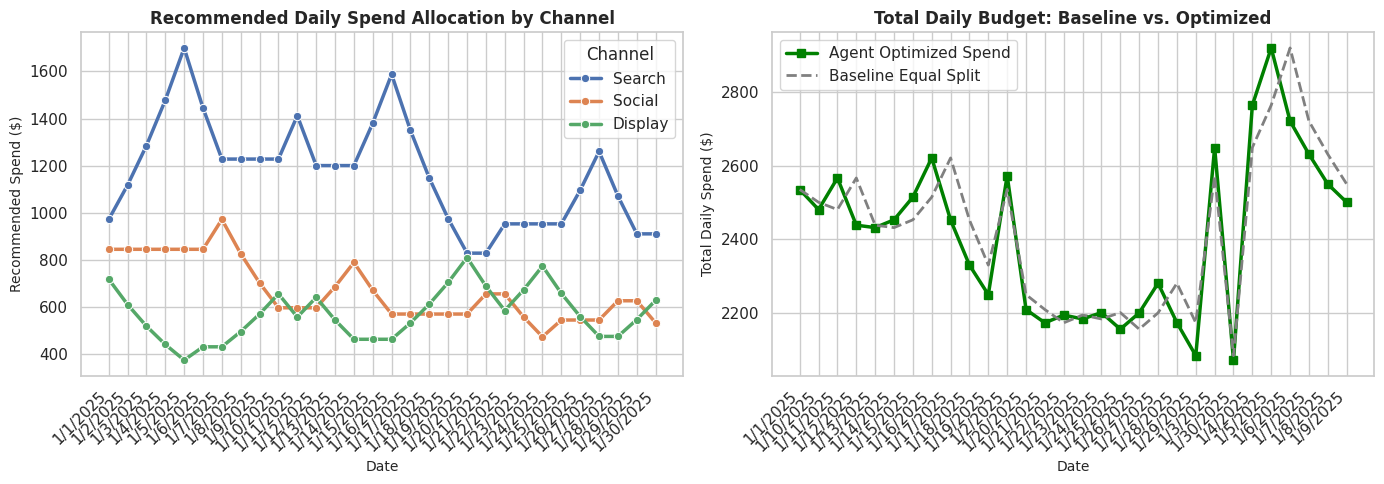

Charts generated successfully and saved as 'performance_charts.png'!


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Load the output log generated by your agent
df_log = pd.read_csv("budget_recommendations_log.csv")

# ----------------------------------------------------
# Chart 1: Recommended Spend Allocation Over Time
# ----------------------------------------------------
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_log,
    x='date',
    y='recommended_spend',
    hue='channel',
    marker='o',
    linewidth=2.5
)
plt.title("Recommended Daily Spend Allocation by Channel", fontsize=12, fontweight='bold')
plt.xlabel("Date", fontsize=10)
plt.ylabel("Recommended Spend ($)", fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Channel")

# ----------------------------------------------------
# Chart 2: Cumulative Spend Comparison (Baseline vs Optimized)
# ----------------------------------------------------
plt.subplot(1, 2, 2)
df_pivot = df_log.pivot(index='date', columns='channel', values='recommended_spend')
df_pivot['Total_Optimized'] = df_pivot.sum(axis=1)
df_pivot['Total_Baseline'] = df_log.groupby('date')['previous_spend'].sum().values

plt.plot(df_pivot.index, df_pivot['Total_Optimized'], label='Agent Optimized Spend', color='green', linewidth=2.5, marker='s')
plt.plot(df_pivot.index, df_pivot['Total_Baseline'], label='Baseline Equal Split', color='gray', linestyle='--', linewidth=2)

plt.title("Total Daily Budget: Baseline vs. Optimized", fontsize=12, fontweight='bold')
plt.xlabel("Date", fontsize=10)
plt.ylabel("Total Daily Spend ($)", fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.legend()

plt.tight_layout()

# Save image for your GitHub repository
plt.savefig("performance_charts.png", dpi=300, bbox_inches='tight')
plt.show()

print("Charts generated successfully and saved as 'performance_charts.png'!")